In [1]:
# Import the following libraries.

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from datetime import datetime as dt
from sklearn.metrics import mean_squared_error, r2_score
from catboost import CatBoostRegressor

In [2]:
# Load the datasets.

train = pd.read_csv("/kaggle/input/datasets/kavithanarsapur/spotter-data/train-test.csv")

validation = pd.read_csv("/kaggle/input/datasets/kavithanarsapur/spotter-data/validation.csv")

In [3]:
# View the train data.

train

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47995,TR-047996,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32
47996,TR-047997,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47997,TR-047998,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36
47998,TR-047999,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46


In [4]:
# View the validation data.

validation

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,TE-011996,Fort Wayne,Louisville,41.31561,-85.36206,37.36588,-87.47153,377.4,Dry Van,38638.0,2025-12-31,1.03391,2.15984
11996,TE-011997,Oklahoma City,Memphis,31.88294,-98.58097,35.56802,-89.52871,707.4,Dry Van,27685.0,2025-12-31,0.99846,2.46279
11997,TE-011998,Nashville,Montgomery,35.29479,-88.08915,31.37602,-86.10743,359.4,Flatbed,35522.0,2025-12-31,0.98564,2.09568
11998,TE-011999,Syracuse,San Antonio,42.80915,-76.89973,29.50969,-98.40059,1750.8,Dry Van,31755.0,2025-12-31,1.03100,1.95125


In [5]:
# Checking the train data for missing values.

train.isnull().sum()

# There are missing values.

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

In [6]:
# Checking the validation data for missing values.

validation.isnull().sum()

# There are missing values.

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64

In [7]:
# Replacing negative weight values with Nan in both train and validation data.

train.loc[train["weight"] < 0, "weight"] = np.nan

validation.loc[validation["weight"] < 0, "weight"] = np.nan

In [8]:
# Replacing missing values with median of respective columns.

train['weight'] = train['weight'].fillna(train['weight'].median())

train['market_index'] = train['market_index'].fillna(train['market_index'].median())

validation['weight'] = validation['weight'].fillna(validation['weight'].median())

validation['market_index'] = validation['market_index'].fillna(validation['market_index'].median())

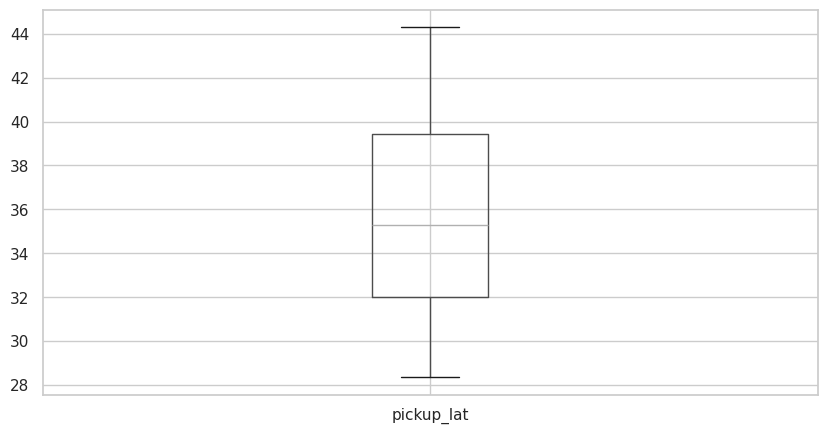

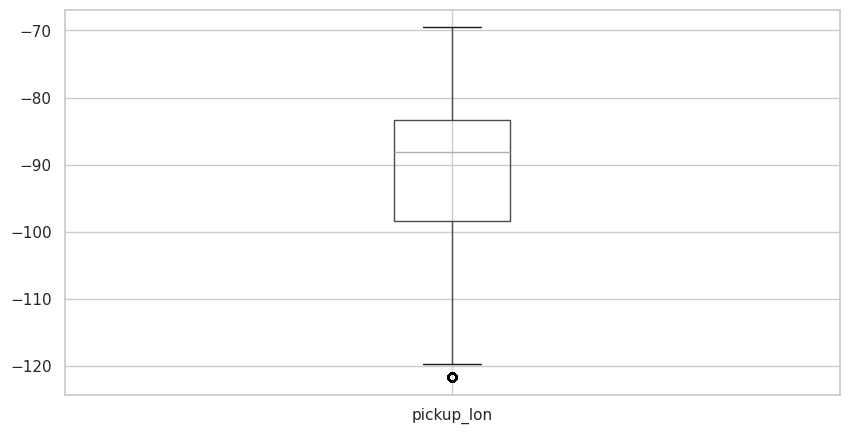

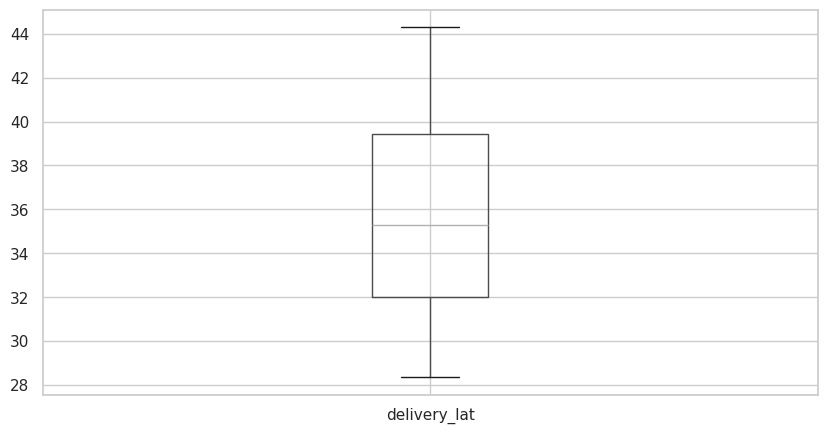

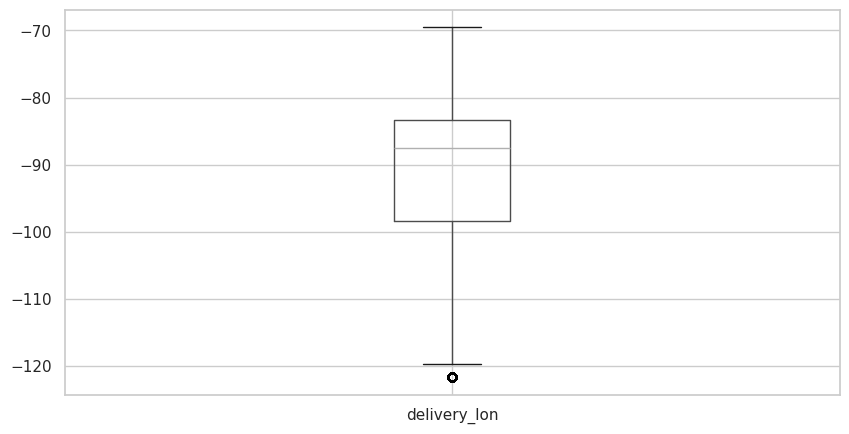

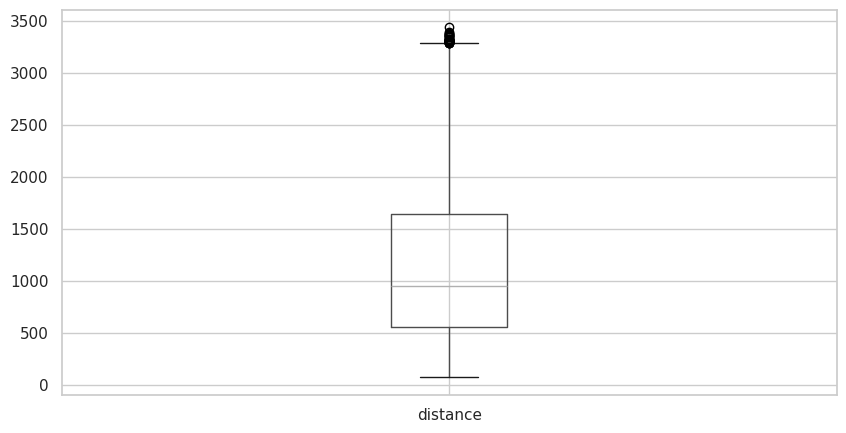

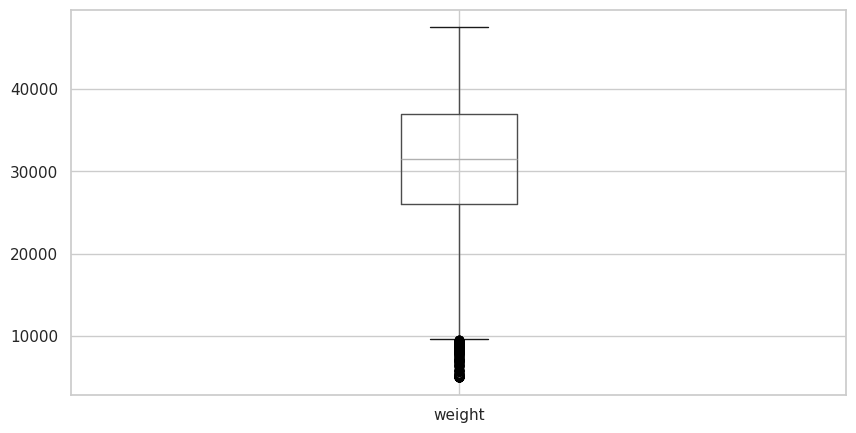

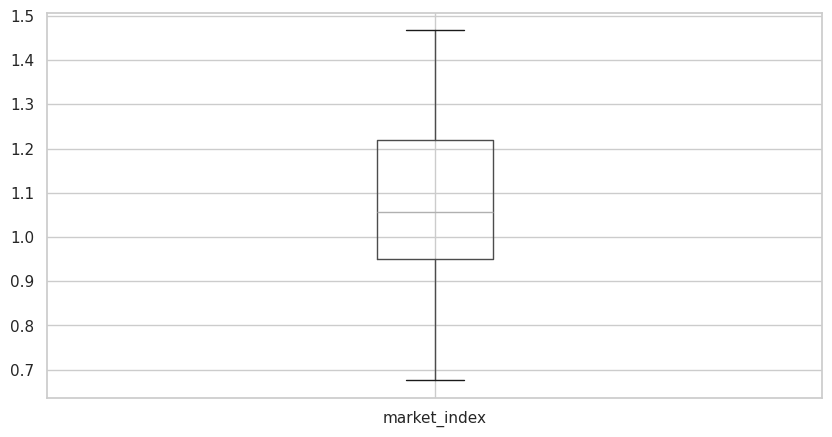

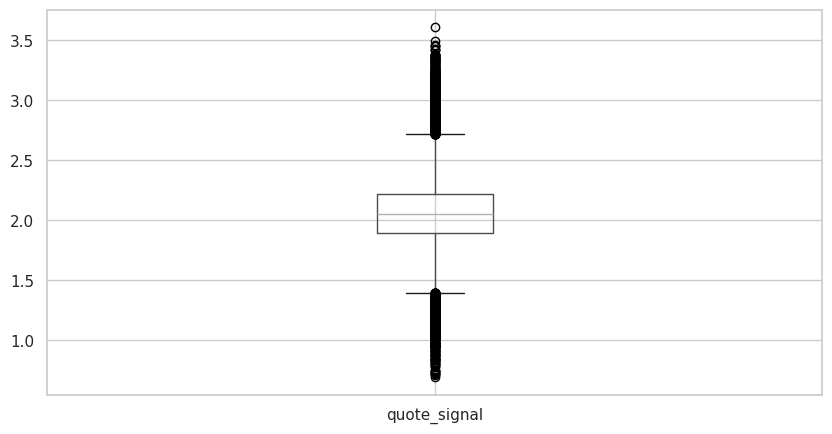

In [9]:
# Plotting box plot to visualize outliers in train data.

numeric_cols = train.select_dtypes(include = 'number')

numeric_cols.drop(["posted_rate"], axis = 1, inplace = True)

for column in numeric_cols:
    plt.figure(figsize = (10,5))
    numeric_cols.boxplot([column])

# Some columns have outliers.

In [10]:
# Flooring and capping the outliers in train data.

for col in numeric_cols.columns:
    Q1 = numeric_cols[col].quantile(0.25)
    Q3 = numeric_cols[col].quantile(0.75)
    IQR = Q3 - Q1 
    Lower_cap  = Q1 - 1.5*IQR
    Upper_cap = Q3 + 1.5*IQR
    numeric_cols[col][numeric_cols[col] <= Lower_cap] = Lower_cap
    numeric_cols[col][numeric_cols[col] >= Upper_cap] = Upper_cap

In [11]:
# Replacing the numeric columns with outliers treated columns.

train.drop(['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance','weight', 'market_index', 'quote_signal'], axis = 1, inplace = True)

numeric_cols.reset_index(drop = True, inplace = True)

train.reset_index(drop = True, inplace = True)

train = pd.concat([train, numeric_cols], axis = 1)

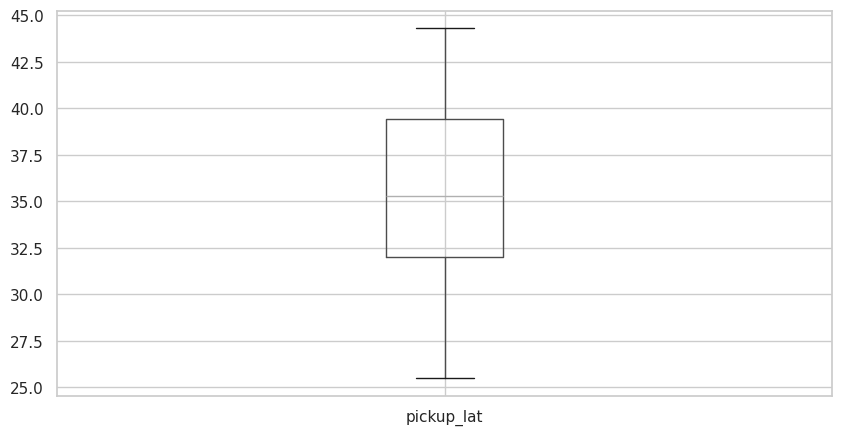

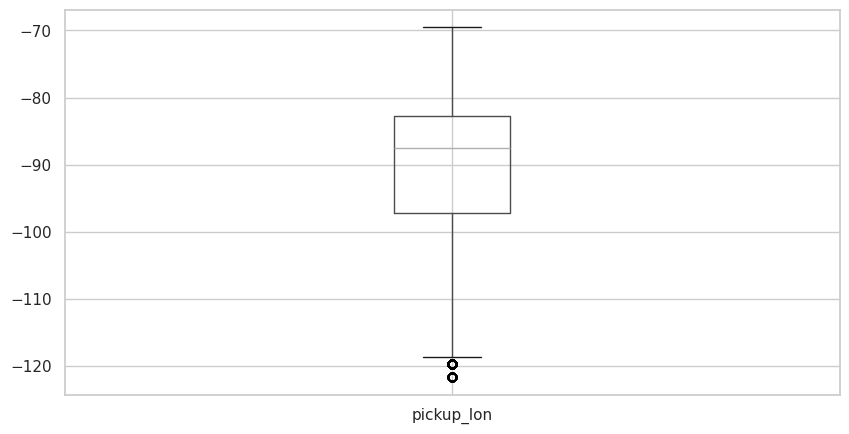

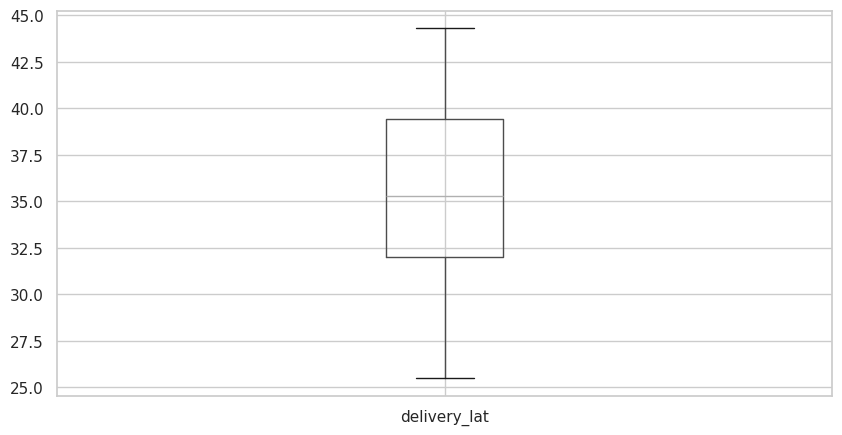

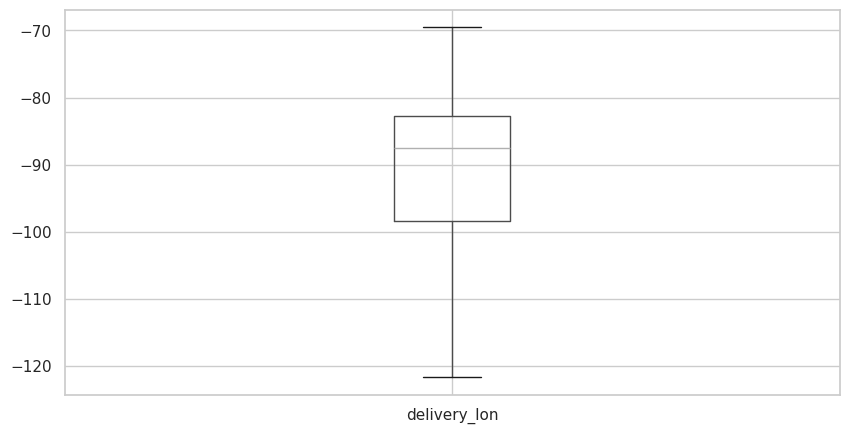

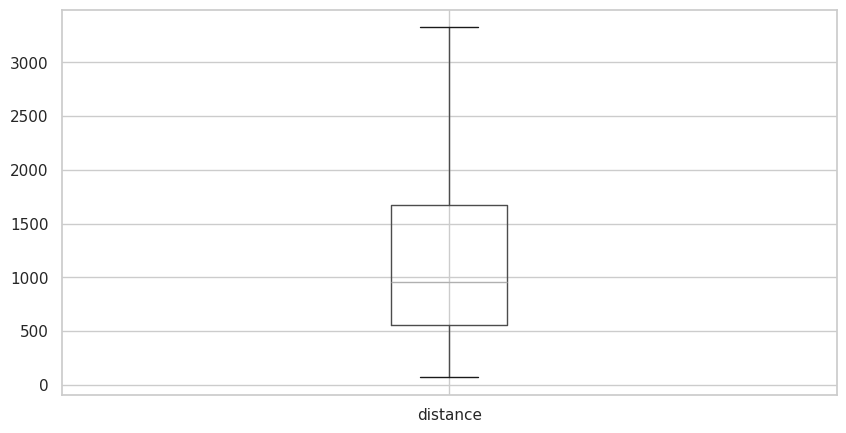

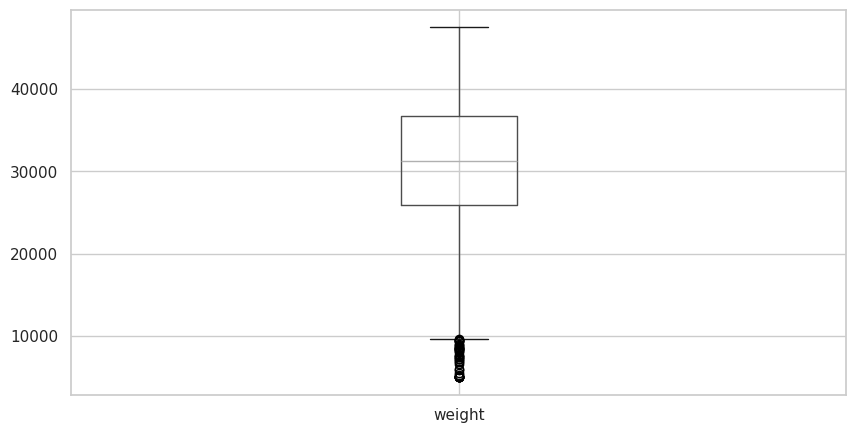

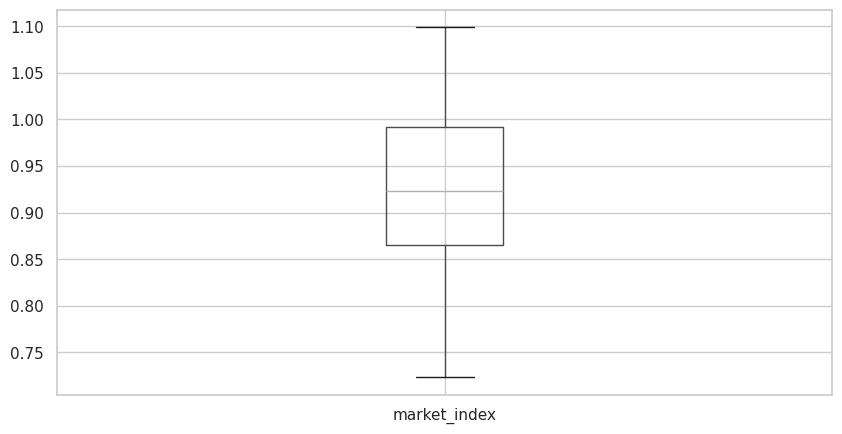

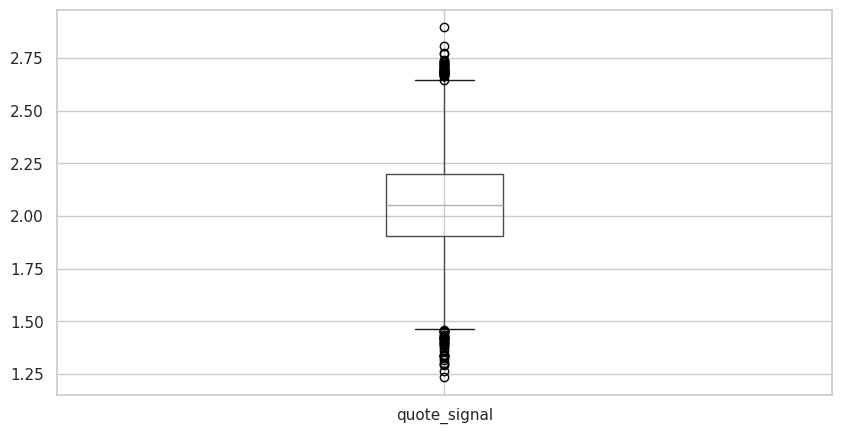

In [12]:
# Visualizing outliers in validation set.

numeric_cols = validation.select_dtypes(include = 'number')

for column in numeric_cols:
    plt.figure(figsize = (10,5))
    numeric_cols.boxplot([column])

# Data has outliers.

In [13]:
# Flooring and capping outliers.

for col in numeric_cols.columns:
    Q1 = numeric_cols[col].quantile(0.25)
    Q3 = numeric_cols[col].quantile(0.75)
    IQR = Q3 - Q1 
    Lower_cap  = Q1 - 1.5*IQR
    Upper_cap = Q3 + 1.5*IQR
    numeric_cols[col][numeric_cols[col] <= Lower_cap] = Lower_cap
    numeric_cols[col][numeric_cols[col] >= Upper_cap] = Upper_cap

In [14]:
# Replacing numeric columns with outlier treated columns in validation data.

validation.drop(['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal'], axis = 1, inplace = True)

numeric_cols.reset_index(drop = True, inplace = True)

validation.reset_index(drop = True, inplace = True)

validation = pd.concat([validation, numeric_cols], axis = 1)

In [15]:

# Function to calculate different metrics from the given data,

def feature_engineering(df):

    df = df.copy()

    # -------------------------------
    # 1. Date-based features
    # -------------------------------

    df['date'] = pd.to_datetime(df['date'])
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['dayofweek'] = df['date'].dt.dayofweek
    df['dayofyear'] = df['date'].dt.dayofyear
    df['weekofyear'] = df['date'].dt.isocalendar().week.astype(float)

    # -------------------------------
    # 2. Geographic distance (Haversine)
    # -------------------------------

    lat1 = np.radians(df['pickup_lat'])
    lon1 = np.radians(df['pickup_lon'])

    lat2 = np.radians(df['delivery_lat'])
    lon2 = np.radians(df['delivery_lon'])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2)**2
    )

    # Prevent floating-point errors
    a = np.clip(a, 0, 1)

    c = 2 * np.arcsin(np.sqrt(a))

    df['geographic_distance_miles'] = 3958.7613 * c

    # -------------------------------
    # 3. Latitude and longitude differences
    # -------------------------------

    df['abs_latitude_diff'] = (
        df['delivery_lat'] - df['pickup_lat']
    ).abs()

    df['abs_longitude_diff'] = (
        df['delivery_lon'] - df['pickup_lon']
    ).abs()

    # -------------------------------
    # 4. Distance-related ratios
    # -------------------------------

    df['reported_to_geographic_distance_ratio'] = (
        df['distance'] /
        df['geographic_distance_miles'].replace(0, np.nan)
    )

    df['distance_per_weight'] = (
        df['distance'] /
        df['weight'].replace(0, np.nan)
    )

    df['weight_per_mile'] = (
        df['weight'] /
        df['distance'].replace(0, np.nan)
    )

    return df

In [16]:
# Apply feature engineering.

train = feature_engineering(train)

validation = feature_engineering(validation)

## Exploratory Data Analysis

## Univariate Analysis

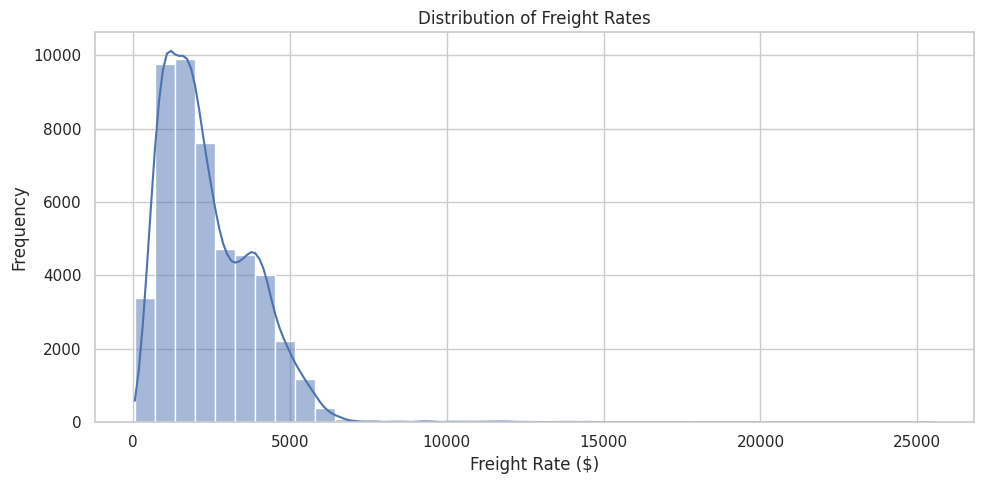

In [17]:
# Freight Rate Distribution.

plt.figure(figsize = (10, 5))
sns.histplot(data = train, x = 'posted_rate', bins = 40, kde = True)
plt.title('Distribution of Freight Rates')
plt.xlabel('Freight Rate ($)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

#### The distribution is right skewed.

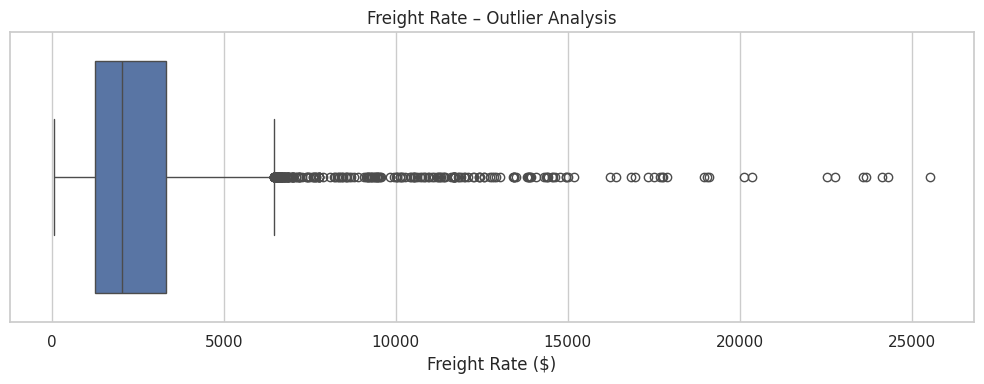

In [18]:
# Outlier detection.

plt.figure(figsize = (10, 4))
sns.boxplot(x = train['posted_rate'])
plt.title('Freight Rate – Outlier Analysis')
plt.xlabel('Freight Rate ($)')
plt.tight_layout()
plt.show()

#### Freight rate has outliers.

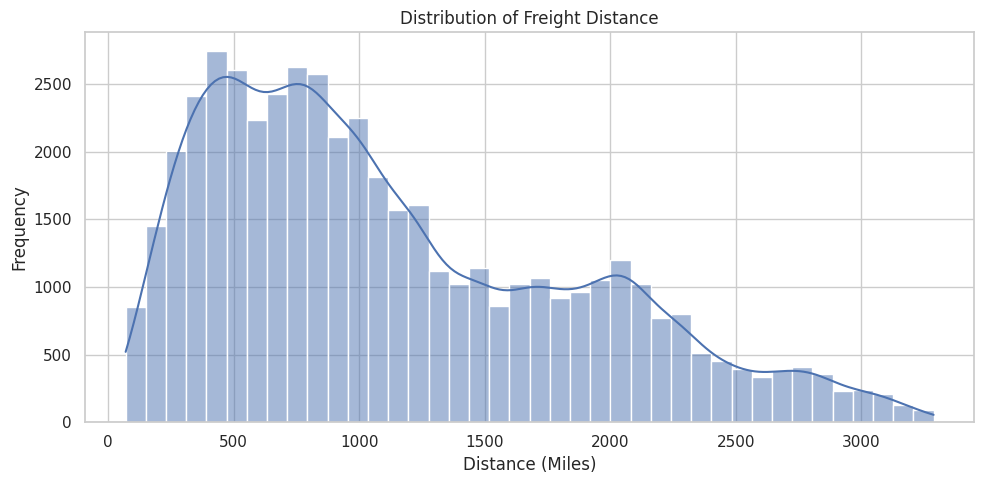

In [19]:
# Distance Distribution.

plt.figure(figsize = (10, 5))
sns.histplot(data = train, x = 'distance', bins = 40, kde = True)
plt.title('Distribution of Freight Distance')
plt.xlabel('Distance (Miles)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

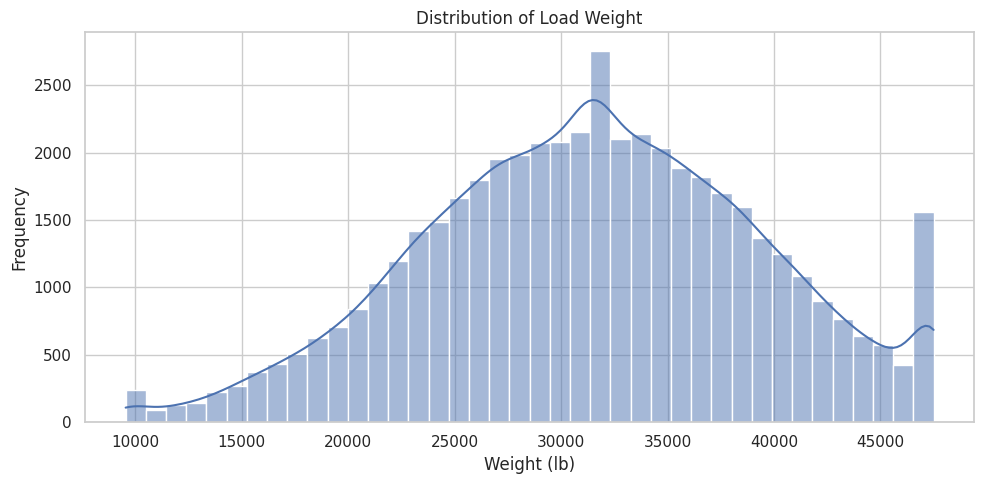

In [20]:
# Weight Distribution.

plt.figure(figsize = (10, 5))
sns.histplot(data = train, x = 'weight', bins = 40, kde = True)
plt.title('Distribution of Load Weight')
plt.xlabel('Weight (lb)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

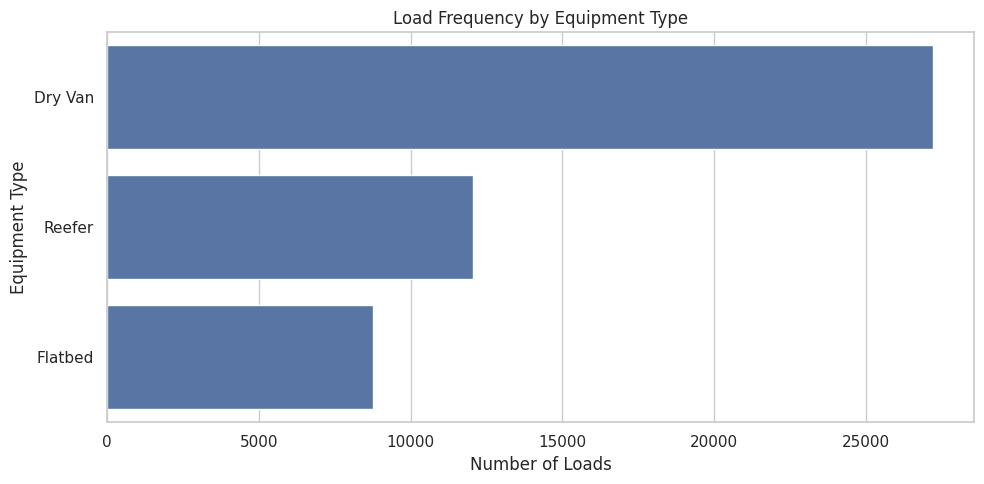

In [21]:
# Equipment type frequency.

plt.figure(figsize = (10, 5))
sns.countplot(data = train, y = 'equipment', order = train['equipment'].value_counts().index)
plt.title('Load Frequency by Equipment Type')
plt.xlabel('Number of Loads')
plt.ylabel('Equipment Type')
plt.tight_layout()
plt.show()

## Bivariate Analysis

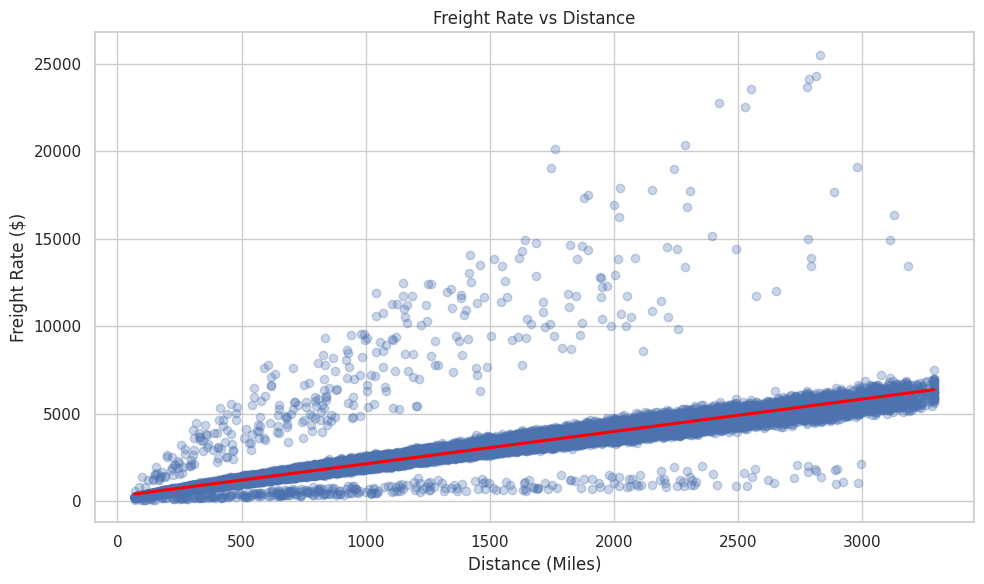

In [22]:
# Freight rate vs Distance.

plt.figure(figsize = (10, 6))
sns.regplot(data = train, x = 'distance', y= 'posted_rate', scatter_kws = {'alpha': 0.3}, line_kws = {'color': 'red'})
plt.title('Freight Rate vs Distance')
plt.xlabel('Distance (Miles)')
plt.ylabel('Freight Rate ($)')
plt.tight_layout()
plt.show()

#### Longer distances may result in higher freight rates.

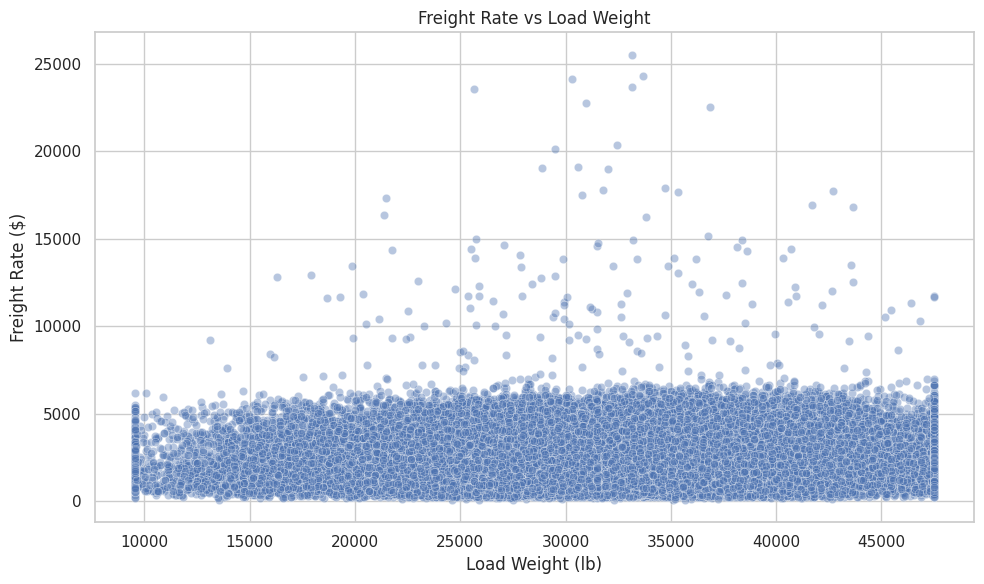

In [23]:
# Freight rate vs Weight.

plt.figure(figsize = (10, 6))
sns.scatterplot(data = train, x = 'weight', y = 'posted_rate', alpha = 0.4)
plt.title('Freight Rate vs Load Weight')
plt.xlabel('Load Weight (lb)')
plt.ylabel('Freight Rate ($)')
plt.tight_layout()
plt.show()

#### Heavier loads are associated with higher freight rates.

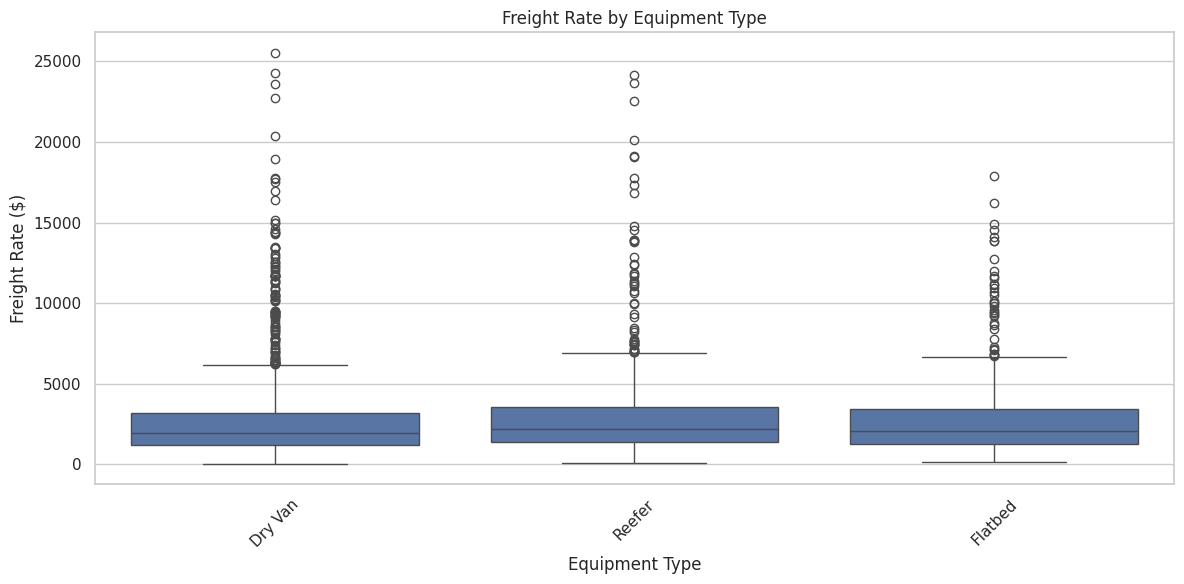

In [24]:
# Freight rate by equipment type.

plt.figure(figsize = (12, 6))
sns.boxplot(data = train, x = 'equipment', y = 'posted_rate')
plt.title('Freight Rate by Equipment Type')
plt.xlabel('Equipment Type')
plt.ylabel('Freight Rate ($)')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

#### Different equipment types may have different pricing patterns due to capacity, availability, and transportation requirements.

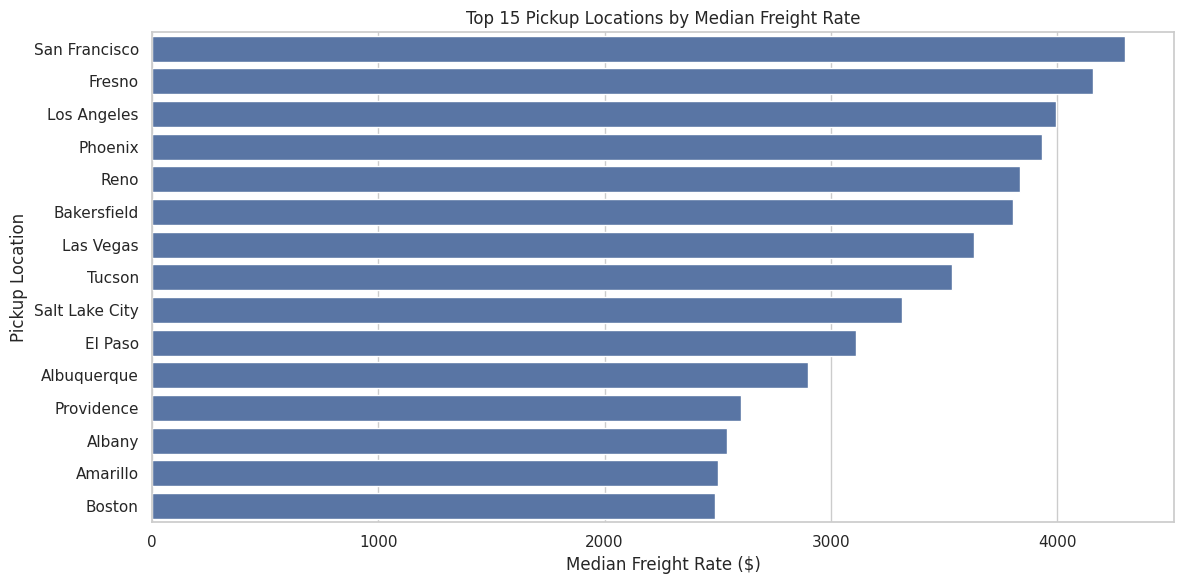

In [25]:
# Freight rate by pickup location.

pickup_rates = (train.groupby('pickup')['posted_rate'].median().sort_values(ascending = False).head(15).reset_index())
plt.figure(figsize = (12, 6))
sns.barplot(data = pickup_rates, x = 'posted_rate', y = 'pickup')
plt.title('Top 15 Pickup Locations by Median Freight Rate')
plt.xlabel('Median Freight Rate ($)')
plt.ylabel('Pickup Location')
plt.tight_layout()
plt.show()

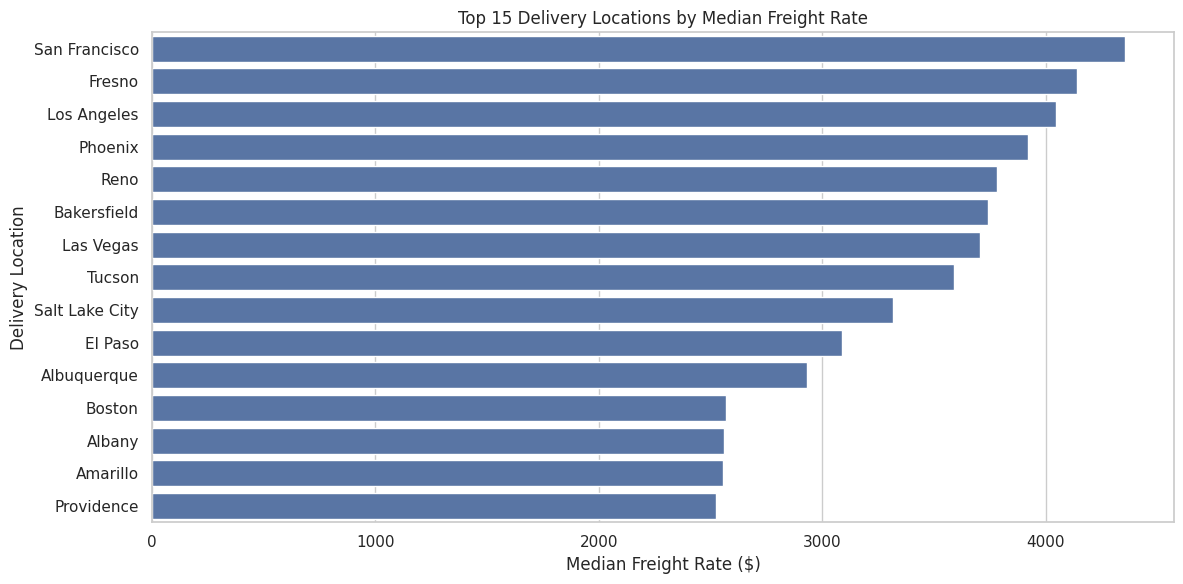

In [26]:
# Freight rate by delivery location.

delivery_rates = (train.groupby('delivery')['posted_rate'].median().sort_values(ascending = False).head(15).reset_index())
plt.figure(figsize = (12, 6))
sns.barplot(data = delivery_rates, x = 'posted_rate', y = 'delivery')
plt.title('Top 15 Delivery Locations by Median Freight Rate')
plt.xlabel('Median Freight Rate ($)')
plt.ylabel('Delivery Location')
plt.tight_layout()
plt.show()

Text(0.5, 0, 'Month')

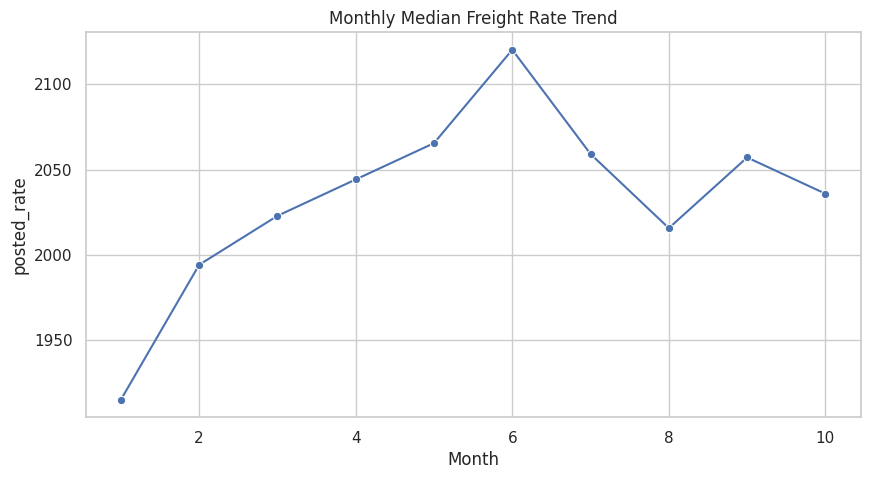

In [27]:
# Freight rate by Month.

monthly_rates = (train.groupby('month')['posted_rate'].median().reset_index())
plt.figure(figsize = (10, 5))
sns.lineplot(data = monthly_rates, x = 'month', y = 'posted_rate', marker = 'o')
plt.title('Monthly Median Freight Rate Trend')
plt.xlabel('Month')

#### Freight rate is high in the month of June.

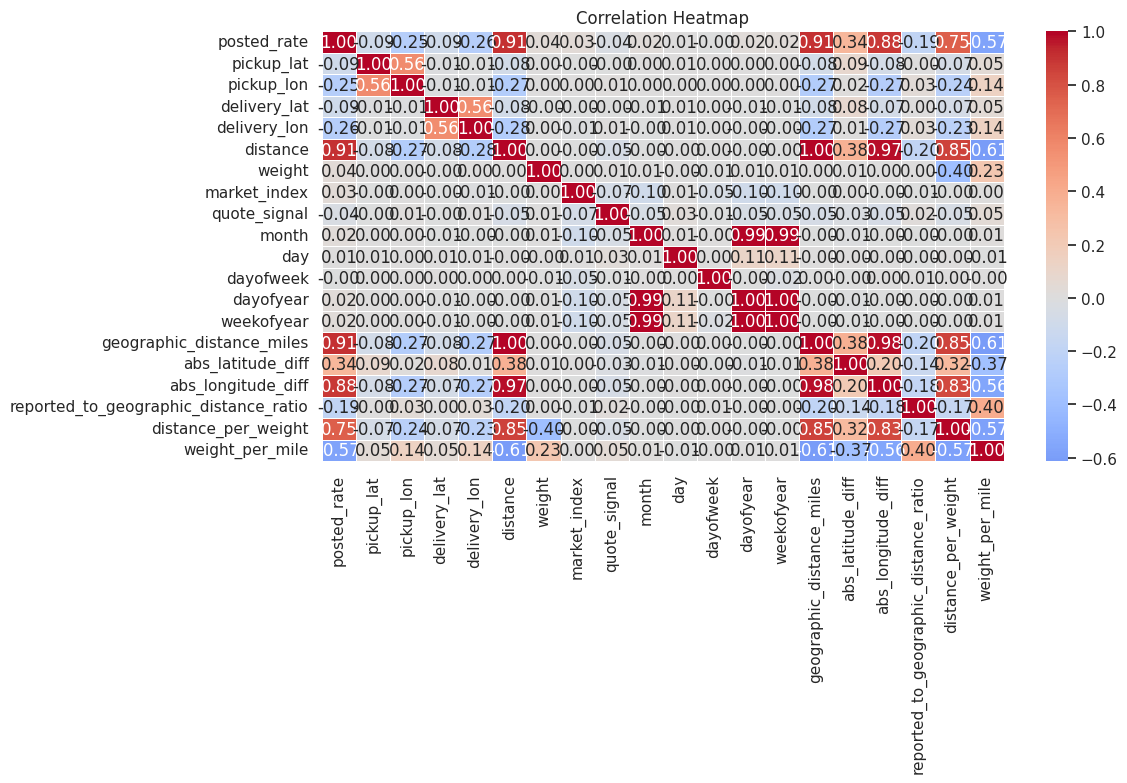

In [28]:
# Correlation Analysis.

numeric_df = train.select_dtypes(include = np.number)
correlation = numeric_df.corr()
plt.figure(figsize = (12, 8))
sns.heatmap(correlation, annot = True, cmap = 'coolwarm', fmt = '.2f', center = 0, linewidths = 0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [29]:
# Extracting only categorical columns.

cat_cols = ['pickup', 'delivery', 'equipment']

In [30]:
# Saving "load_id" and "date" columns of train and validation columns.

tr_col = train[['load_id', 'date']]

val_col = validation[['load_id', 'date']]

In [31]:
# Dropping "load_id" and "date" columns of train and validation columns before model building.

train.drop(['load_id', 'date'], axis = 1, inplace = True)

validation.drop(['load_id', 'date'], axis = 1, inplace = True)

## Model Building 

In [32]:
# Storing "posted_rate" in "y" and other variables in "X".

y = train['posted_rate']

X = train.drop(['posted_rate'], axis = 1)

In [33]:
# Splitting data into train and test data.

X_train, X_test, Y_train, Y_test = train_test_split(X, y, random_state = 100, test_size = 0.3)

In [34]:
# Building CatBoostRegressor model.

model = CatBoostRegressor(loss_function = 'RMSE')

# Fit the model on the training data with verbose logging every 100 iterations

model.fit(X_train, np.log1p(Y_train), cat_features = cat_cols, verbose = 100)

Learning rate set to 0.071341
0:	learn: 0.6240848	total: 73.6ms	remaining: 1m 13s
100:	learn: 0.1541589	total: 1.59s	remaining: 14.2s
200:	learn: 0.1518167	total: 2.98s	remaining: 11.9s
300:	learn: 0.1499111	total: 4.37s	remaining: 10.1s
400:	learn: 0.1482764	total: 5.81s	remaining: 8.69s
500:	learn: 0.1466550	total: 7.35s	remaining: 7.32s
600:	learn: 0.1448149	total: 8.84s	remaining: 5.87s
700:	learn: 0.1433247	total: 10.3s	remaining: 4.4s
800:	learn: 0.1418387	total: 11.8s	remaining: 2.94s
900:	learn: 0.1405341	total: 13.3s	remaining: 1.46s
999:	learn: 0.1388965	total: 14.8s	remaining: 0us


CatBoostRegressor(loss_function='RMSE')

In [35]:
# Predicting the test data.

y_pred = model.predict(X_test)

In [36]:
# Calculating RMSE and R2 score.

print("Validation RMSE: ", np.sqrt(mean_squared_error(np.log1p(Y_test), y_pred)))

print("R2 Score: ", r2_score(np.log1p(Y_test), y_pred))

Validation RMSE:  0.15366577564493278
R2 Score:  0.9471818445079662


#### CatboostRegressor model is performing very well on unseen data.

In [37]:
# Predicting Validation data and storing the predicted rates as "validation_predictions.csv". 

predicted_rate = np.expm1(model.predict(validation))

predicted_rate = np.maximum(predicted_rate, 0)

validation_predictions = pd.DataFrame({
    "load_id": val_col["load_id"],
    "predicted_rate": predicted_rate
})

validation_predictions.to_csv('validation_predictions.csv', index = False)

In [38]:
# Extract feature importance.

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

# Sort in descending order.

feature_importance = feature_importance.sort_values(by = 'Importance', ascending = False).reset_index(drop = True)

print(feature_importance)

                                  Feature  Importance
0               geographic_distance_miles   46.748079
1                                distance   35.456158
2                      abs_longitude_diff    5.301395
3                               equipment    2.932017
4                         weight_per_mile    1.162184
5                                  weight    1.149304
6                            market_index    1.103130
7   reported_to_geographic_distance_ratio    0.740554
8                            quote_signal    0.578270
9                       abs_latitude_diff    0.571785
10                              dayofyear    0.537416
11                             pickup_lat    0.516376
12                           delivery_lat    0.488685
13                           delivery_lon    0.393828
14                                    day    0.365472
15                    distance_per_weight    0.347099
16                             pickup_lon    0.342370
17                          

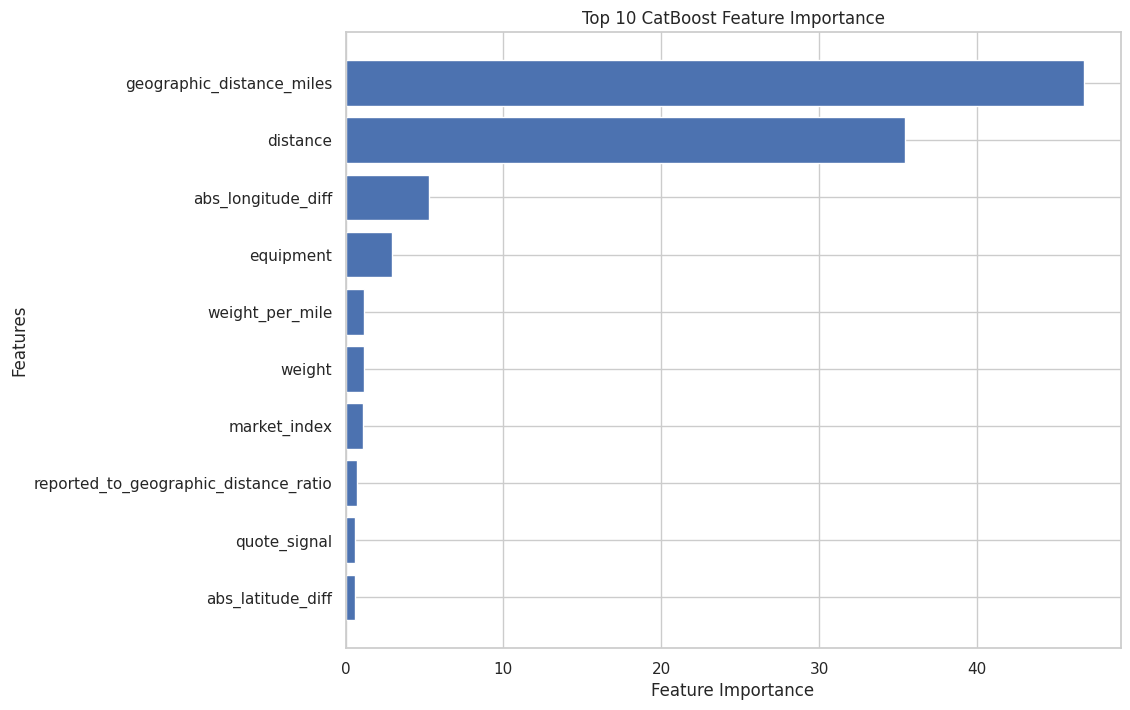

In [39]:
# Visualize top 10 important features.

top_features = feature_importance.head(10)

plt.figure(figsize = (10, 8))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 10 CatBoost Feature Importance')

plt.gca().invert_yaxis()
plt.show()

## Applying Scorer.py to generate fixed december prediction chart.

In [40]:
from pathlib import Path

# --------------------------------------------------
# 1. Generate dates for December 2025
# --------------------------------------------------

december_dates = pd.date_range(
    start="2025-12-01",
    end="2025-12-31",
    freq="D"
)

# --------------------------------------------------
# 2. Retrieve route coordinates from training data
# --------------------------------------------------

pickup_coordinates = (
    train.groupby("pickup")[["pickup_lat", "pickup_lon"]]
    .median()
)

delivery_coordinates = (
    train.groupby("delivery")[["delivery_lat", "delivery_lon"]]
    .median()
)

if "Lexington" not in pickup_coordinates.index:
    raise ValueError("Lexington coordinates not found in training data.")

if "Fort Wayne" not in delivery_coordinates.index:
    raise ValueError("Fort Wayne coordinates not found in training data.")

pickup_lat = pickup_coordinates.loc["Lexington", "pickup_lat"]
pickup_lon = pickup_coordinates.loc["Lexington", "pickup_lon"]

delivery_lat = delivery_coordinates.loc["Fort Wayne", "delivery_lat"]
delivery_lon = delivery_coordinates.loc["Fort Wayne", "delivery_lon"]

# --------------------------------------------------
# 3. Retrieve median values for other model features
# --------------------------------------------------

base_values = X_train.median(numeric_only=True).to_dict()

for col in cat_cols:
    base_values[col] = X_train[col].mode(dropna=True).iloc[0]

# --------------------------------------------------
# 4. Create 31 December input records
# --------------------------------------------------

december_raw = pd.DataFrame(
    [base_values.copy() for _ in december_dates]
)

december_raw["pickup"] = "Lexington"
december_raw["delivery"] = "Fort Wayne"
december_raw["equipment"] = "Dry Van"

december_raw["distance"] = 360.0
december_raw["weight"] = 32000.0

december_raw["pickup_lat"] = pickup_lat
december_raw["pickup_lon"] = pickup_lon

december_raw["delivery_lat"] = delivery_lat
december_raw["delivery_lon"] = delivery_lon

december_raw["date"] = december_dates

# --------------------------------------------------
# 5. Apply the SAME feature engineering function
# --------------------------------------------------

december_features = feature_engineering(december_raw)

# Match the exact training feature columns and order
X_december = december_features.reindex(
    columns=X_train.columns
)

# Check missing model features
if X_december.isnull().any().any():
    missing = X_december.columns[
        X_december.isnull().any()
    ].tolist()
    raise ValueError(f"Missing feature values: {missing}")

# --------------------------------------------------
# 6. Generate predictions using existing CatBoost model
# --------------------------------------------------

log_predictions = model.predict(X_december)

# Convert log predictions back to original freight rates
december_predicted_rate = np.expm1(log_predictions)

# Ensure all predicted rates are positive
december_predicted_rate = np.maximum(
    december_predicted_rate, 0.01
)

# --------------------------------------------------
# 7. Create December prediction dataframe
# --------------------------------------------------

december_predictions = pd.DataFrame({
    "pickup": "Lexington",
    "delivery": "Fort Wayne",
    "distance": 360.0,
    "equipment": "Dry Van",
    "weight": 32000.0,
    "date": december_dates,
    "predicted_rate": december_predicted_rate
})

# --------------------------------------------------
# 8. Save December predictions CSV
# --------------------------------------------------

december_predictions.to_csv(
    "december_chart_inputs.csv",
    index=False
)

print("December predictions generated successfully.")

print(december_predictions.to_string(index=False))

print("\nPrediction statistics:")
print(december_predictions["predicted_rate"].describe())


December predictions generated successfully.
   pickup   delivery  distance equipment  weight       date  predicted_rate
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-01      870.606798
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-02      865.585346
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-03      866.984975
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-04      866.421565
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-05      860.742461
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-06      860.378159
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-07      858.457802
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-08      859.734154
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-09      864.201936
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-10      865.653874
Lexington Fort Wayne     360.0   Dry Van 32000.0 2025-12-11      864.141122
Lexington Fort Wayne     360.0   Dry Van 32

In [42]:
# Running the scorer.

!python /kaggle/input/datasets/kavithanarsapur/scorer/score.py \
    --predictions //kaggle/working/validation_predictions.csv \
    --december-predictions //kaggle/working/december_chart_inputs.csv \
    --output-dir /kaggle/working/scorer_results

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /kaggle/working/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


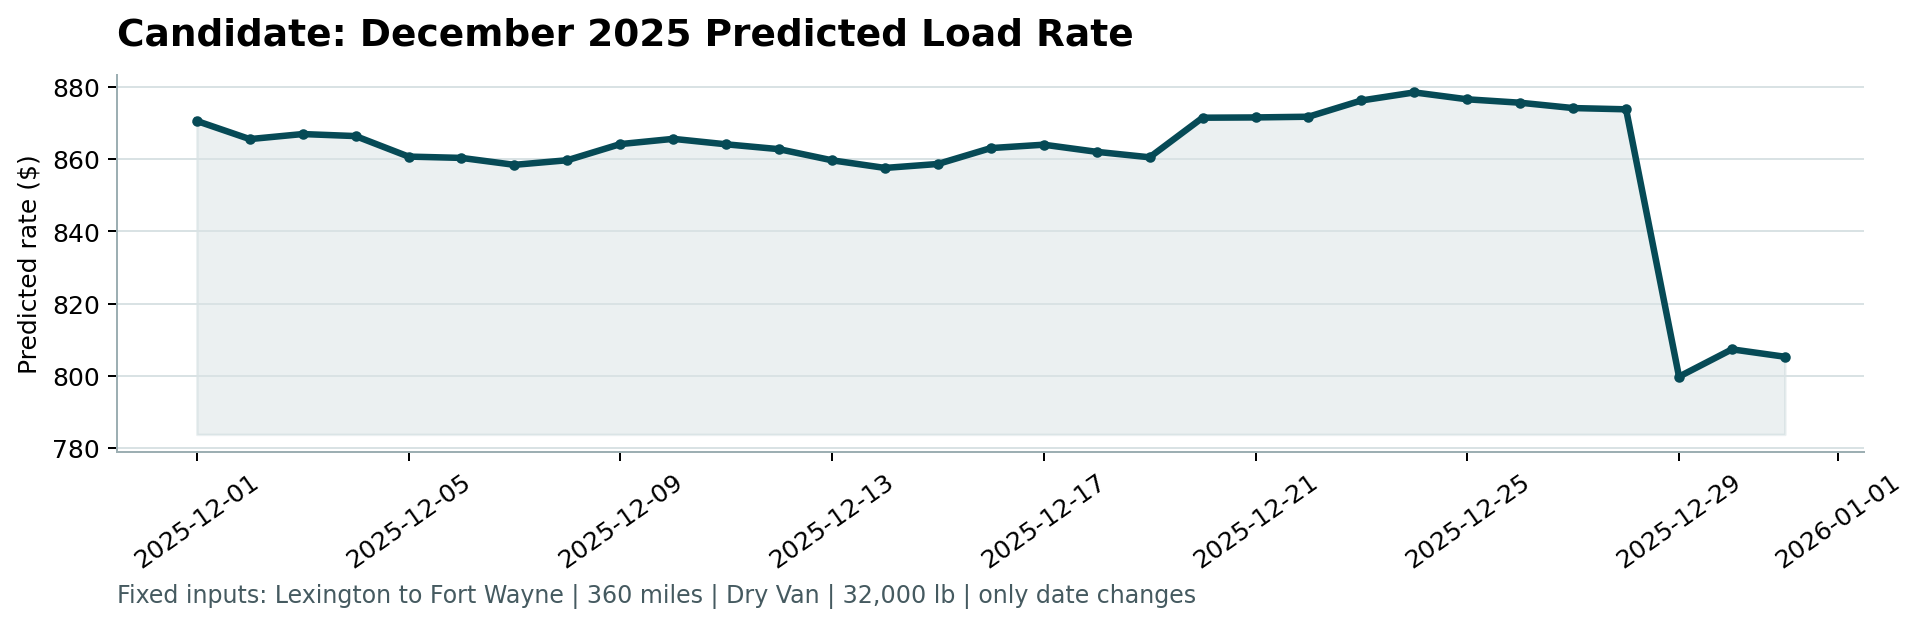

In [43]:
# Displaying December prediction chart.

from IPython.display import Image, display

display(Image("/kaggle/working/scorer_results/candidate_december.png"))